# 03 — Exploratory Data Analysis

**Goal:** understand the catalogue, rating behaviour, popularity, genres, and release-year patterns before modelling.

## 1. Load processed data and plotting libraries

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# Keep paths consistent whether the notebook is launched from the project root or 02_Notebooks.
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "02_Notebooks" else CWD
DATA_RAW = PROJECT_ROOT / "01_Data" / "Raw"
DATA_PROCESSED = PROJECT_ROOT / "01_Data" / "Processed"
MODELS = PROJECT_ROOT / "03_Models"
VISUALS = PROJECT_ROOT / "05_Visualizations"
for folder in [DATA_RAW, DATA_PROCESSED, MODELS, VISUALS]:
    folder.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
movies = pd.read_pickle(DATA_PROCESSED / "movies_processed.pkl")
ratings = pd.read_csv(DATA_PROCESSED / "ratings_processed.csv")
sns.set_theme()
print(f"Movies: {len(movies):,} | Users: {ratings.userId.nunique():,} | Ratings: {len(ratings):,}")

Project root: D:\DataScience\notebooks\CineMatch_Ready_Notebooks
Movies: 9,742 | Users: 610 | Ratings: 100,836


## 2. Rating distribution

This shows which rating values users tend to give. The shape is useful context, but it does not by itself measure recommendation quality.

,number_of_ratings
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


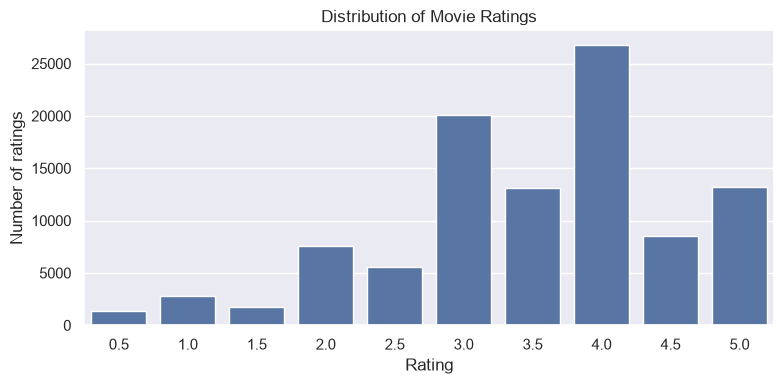

In [3]:
rating_counts = ratings["rating"].value_counts().sort_index()
display(rating_counts.to_frame("number_of_ratings"))
plt.figure(figsize=(8,4))
sns.barplot(x=rating_counts.index, y=rating_counts.values)
plt.title("Distribution of Movie Ratings"); plt.xlabel("Rating"); plt.ylabel("Number of ratings")
plt.tight_layout(); plt.show()

## 3. Most-rated movies

A high rating count is a measure of popularity/visibility, not necessarily quality.

,title,rating_count,average_rating
314,Forrest Gump (1994),329,4.164134
277,"Shawshank Redemption, The (1994)",317,4.429022
257,Pulp Fiction (1994),307,4.197068
510,"Silence of the Lambs, The (1991)",279,4.161290
1938,"Matrix, The (1999)",278,4.192446
224,Star Wars: Episode IV - A New Hope (1977),251,4.231076
418,Jurassic Park (1993),238,3.750000
97,Braveheart (1995),237,4.031646
507,Terminator 2: Judgment Day (1991),224,3.970982
461,Schindler's List (1993),220,4.225000


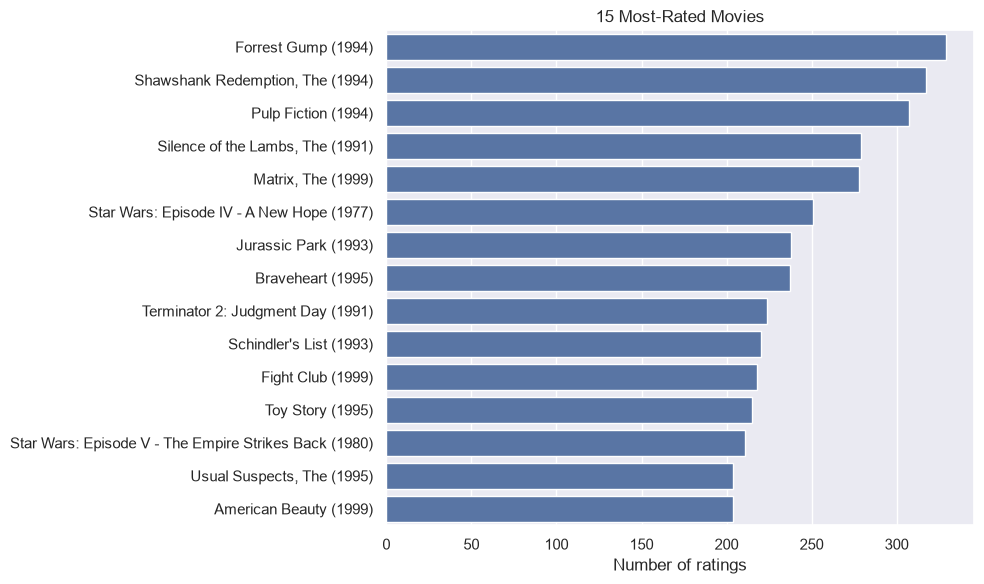

In [4]:
movie_stats = ratings.groupby("movieId").agg(
    rating_count=("rating", "count"), average_rating=("rating", "mean")
).reset_index().merge(movies[["movieId","title"]], on="movieId", how="left")
most_rated = movie_stats.nlargest(15, "rating_count")
display(most_rated[["title","rating_count","average_rating"]])
plt.figure(figsize=(10,6))
sns.barplot(data=most_rated, y="title", x="rating_count")
plt.title("15 Most-Rated Movies"); plt.xlabel("Number of ratings"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 4. Highest-rated movies with a minimum rating threshold

We require at least 50 ratings to reduce the chance that a movie with one unusually high rating dominates the list. Change the threshold if your analysis needs it.

In [5]:
MIN_RATINGS = 50
qualified = movie_stats[movie_stats["rating_count"] >= MIN_RATINGS]
top_rated = qualified.sort_values(["average_rating","rating_count"], ascending=False).head(15)
display(top_rated[["title","average_rating","rating_count"]])

,title,average_rating,rating_count
277,"Shawshank Redemption, The (1994)",4.429022,317
659,"Godfather, The (1972)",4.289062,192
2224,Fight Club (1999),4.272936,218
974,Cool Hand Luke (1967),4.271930,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.268041,97
686,Rear Window (1954),4.261905,84
921,"Godfather: Part II, The (1974)",4.259690,129
6298,"Departed, The (2006)",4.252336,107
913,Goodfellas (1990),4.250000,126
694,Casablanca (1942),4.240000,100


## 5. Genre popularity

A movie can belong to multiple genres, so each movie contributes once to each genre it carries.

,movie_count
genre_list,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


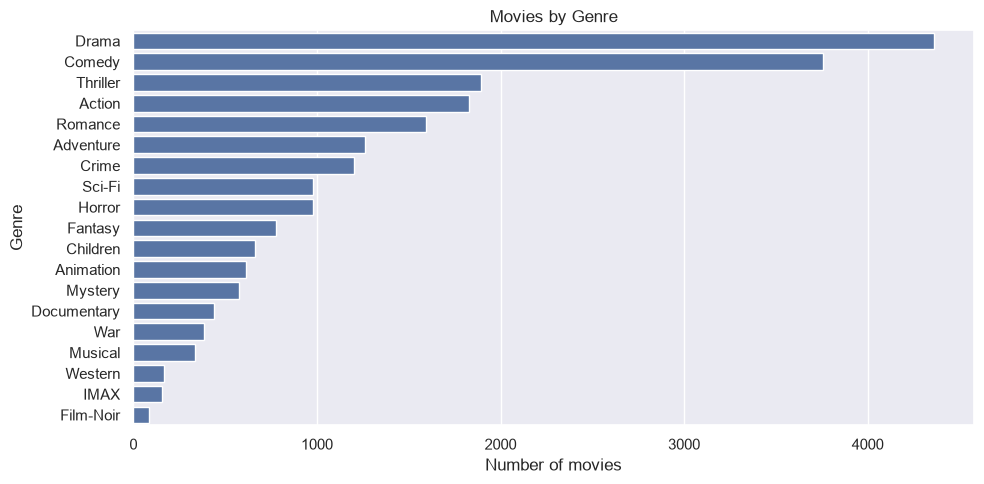

In [6]:
genre_counts = (movies.explode("genre_list")
                .dropna(subset=["genre_list"])
                .groupby("genre_list")["movieId"].nunique()
                .sort_values(ascending=False))
display(genre_counts.to_frame("movie_count"))
plt.figure(figsize=(10,5))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Movies by Genre"); plt.xlabel("Number of movies"); plt.ylabel("Genre")
plt.tight_layout(); plt.show()

## 6. Release-year distribution

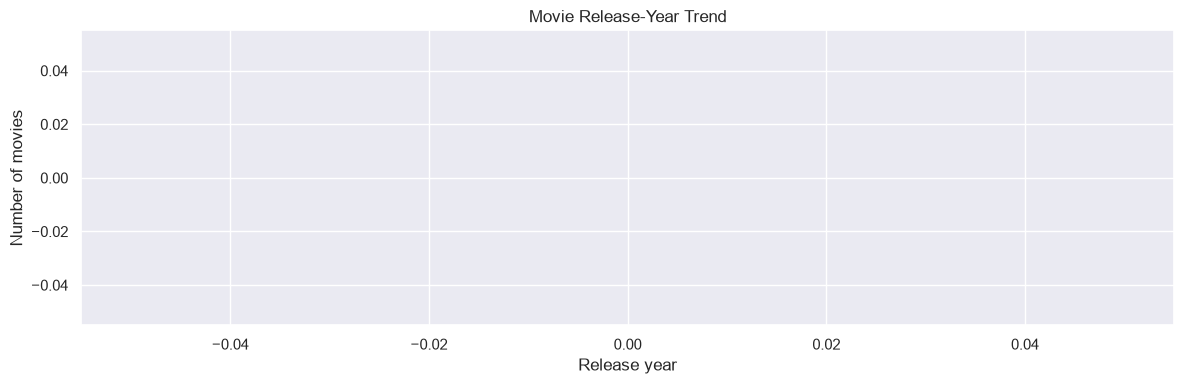

In [7]:
year_counts = movies.dropna(subset=["release_year"]).groupby("release_year")["movieId"].nunique()
plt.figure(figsize=(12,4))
year_counts.plot()
plt.title("Movie Release-Year Trend"); plt.xlabel("Release year"); plt.ylabel("Number of movies")
plt.tight_layout(); plt.show()

## 7. User and movie rating activity

These distributions are usually skewed: a small group of users or movies may account for many interactions.

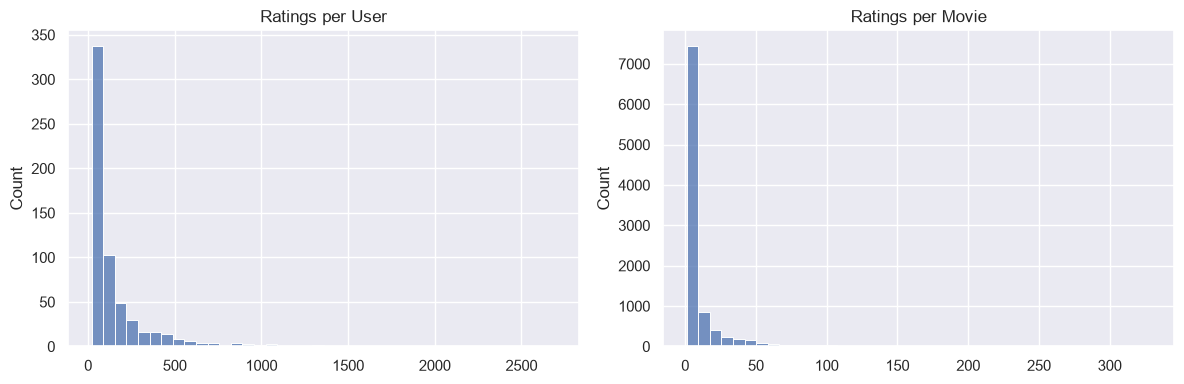

Median ratings/user: 70.5
Median ratings/movie: 3.0


In [8]:
ratings_per_user = ratings.groupby("userId").size()
ratings_per_movie = ratings.groupby("movieId").size()
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.histplot(ratings_per_user, bins=40, ax=axes[0]); axes[0].set_title("Ratings per User")
sns.histplot(ratings_per_movie, bins=40, ax=axes[1]); axes[1].set_title("Ratings per Movie")
plt.tight_layout(); plt.show()
print("Median ratings/user:", ratings_per_user.median())
print("Median ratings/movie:", ratings_per_movie.median())

## 8. Interactive rating chart and findings prompts

In [9]:
fig = px.histogram(ratings, x="rating", title="Interactive Rating Distribution",
                   nbins=10, labels={"rating":"Rating"})
fig.show()

print("DATA-BASED OBSERVATIONS TO DISCUSS")
print("- Most-rated titles identify popular items in this sample.")
print("- Average ratings should be interpreted alongside rating counts.")
print("- Genre counts overlap because movies can have multiple genres.")
print("- Sparse user/movie activity helps explain why collaborative filtering is challenging.")

DATA-BASED OBSERVATIONS TO DISCUSS
- Most-rated titles identify popular items in this sample.
- Average ratings should be interpreted alongside rating counts.
- Genre counts overlap because movies can have multiple genres.
- Sparse user/movie activity helps explain why collaborative filtering is challenging.


## Completion check

EDA charts are displayed in the notebook. Next: **04_Content_Based_Recommendation.ipynb**.